# Câu 3 (Mở rộng Học sâu): Thực nghiệm mô hình mạng nơ-ron BiLSTM & DistilBERT

**Mục tiêu:**
1. Xây dựng và huấn luyện mạng nơ-ron hồi quy hai chiều **BiLSTM (PyTorch Embedding 128 chiều + Global Avg/Max Pooling)** có trọng số lớp.
2. Tinh chỉnh (Fine-tune) mô hình ngôn ngữ tiền huấn luyện **DistilBERT (`distilbert-base-uncased`)** với hàm mất mát `CrossEntropyLoss` có trọng số lớp.
3. Phân tích sự đánh đổi giữa **Hiệu năng (F1 / PR-AUC)**, **Thời gian huấn luyện/suy luận**, **Dung lượng mô hình** và **Khả năng giải thích** khi triển khai ứng dụng thực tế.

In [1]:
# === THIẾT LẬP MÔI TRƯỜNG & NẠP THƯ VIỆN DỰ ÁN ===
import os, sys, subprocess
from pathlib import Path

os.environ.setdefault("OPENBLAS_NUM_THREADS", "1")
os.environ.setdefault("OMP_NUM_THREADS", "1")
REPO_URL = "https://github.com/nhungoc-1/DoAnKHDL_DeTai_Tweet-Hate.git"

IN_COLAB = "google.colab" in sys.modules
if IN_COLAB:
    print("[SETUP] Đang khởi tạo môi trường Google Colab...", flush=True)
    for candidate in [
        Path("/content/DoAnKHDL_DeTai_Tweet-Hate"),
        Path("/content/drive/MyDrive/DoAnKHDL_DeTai_Tweet-Hate"),
        Path("/content/drive/MyDrive/DO_AN_KHDL"),
        Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd(),
    ]:
        if (candidate / "config.yaml").exists():
            PROJECT_DIR = candidate
            subprocess.run(["git", "-C", str(PROJECT_DIR), "pull", "--ff-only"], check=False)
            break
    else:
        PROJECT_DIR = Path("/content/DoAnKHDL_DeTai_Tweet-Hate")
        print(f"[SETUP] Đang tải dự án từ GitHub vào {PROJECT_DIR} (mất ~3 giây)...", flush=True)
        subprocess.run(["git", "clone", "--depth", "1", REPO_URL, str(PROJECT_DIR)], check=True)
    print("[SETUP] Đang kiểm tra & cài đặt các thư viện bổ sung (mất ~5-10 giây)...", flush=True)
    subprocess.run([
        sys.executable, "-m", "pip", "install", "-q",
        "imbalanced-learn", "emoji", "kagglehub", "datasets",
        "pyvi", "langdetect", "python-docx", "python-pptx", "wordcloud"
    ], check=False)
    import nltk
    for pkg in ["stopwords", "wordnet", "omw-1.4"]:
        nltk.download(pkg, quiet=True)
else:
    PROJECT_DIR = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()

os.chdir(PROJECT_DIR)
if str(PROJECT_DIR) not in sys.path:
    sys.path.insert(0, str(PROJECT_DIR))

from src.utils import set_seed, load_config, mask_profanity
set_seed(42)
CFG = load_config()
(PROJECT_DIR / "db").mkdir(parents=True, exist_ok=True)
print(f"[HOÀN TẤT] IN_COLAB = {IN_COLAB} | PROJECT_DIR = {PROJECT_DIR}")

[SETUP] PROJECT_DIR = D:\DO_AN_KHDL


## 1. Kết quả Thực nghiệm BiLSTM & DistilBERT so với Mô hình Cổ điển Tối ưu

Thiết bị chạy thực nghiệm (CUDA Available): False

=== Lịch sử huấn luyện BiLSTM ===


,epoch,train_loss,val_f1,val_pr_auc
0,1,0.9969,0.3073,0.3122
1,2,0.6800,0.4530,0.5299
2,3,0.4748,0.4968,0.5789
3,4,0.3640,0.5262,0.6109
4,5,0.2874,0.5432,0.6182
5,6,0.2393,0.5973,0.6168


Metric Validation BiLSTM: {'precision_pos': 0.5663, 'recall_pos': 0.6318, 'f1_pos': 0.5973, 'f1_macro': 0.7837, 'accuracy': 0.9445, 'balanced_acc': 0.799, 'roc_auc': 0.9133, 'pr_auc': 0.6168, 'mcc': 0.5685, 'tn': 3839, 'fp': 134, 'fn': 102, 'tp': 175, 'fit_seconds': 83.86, 'predict_ms_per_1k': 77.395, 'device': 'cpu'}

=== Lịch sử huấn luyện DistilBERT ===


,epoch,train_loss,val_f1,val_pr_auc
0,1,0.5298,0.4042,0.508
1,2,0.3340,0.4434,0.560


Metric Validation DistilBERT: {'precision_pos': 0.301, 'recall_pos': 0.8412, 'f1_pos': 0.4434, 'f1_macro': 0.6824, 'accuracy': 0.8624, 'balanced_acc': 0.8525, 'roc_auc': 0.9266, 'pr_auc': 0.56, 'mcc': 0.4509, 'tn': 3432, 'fp': 541, 'fn': 44, 'tp': 233, 'fit_seconds': 257.329, 'predict_ms_per_1k': 17224.577, 'device': 'cpu', 'n_train_used': 1500}


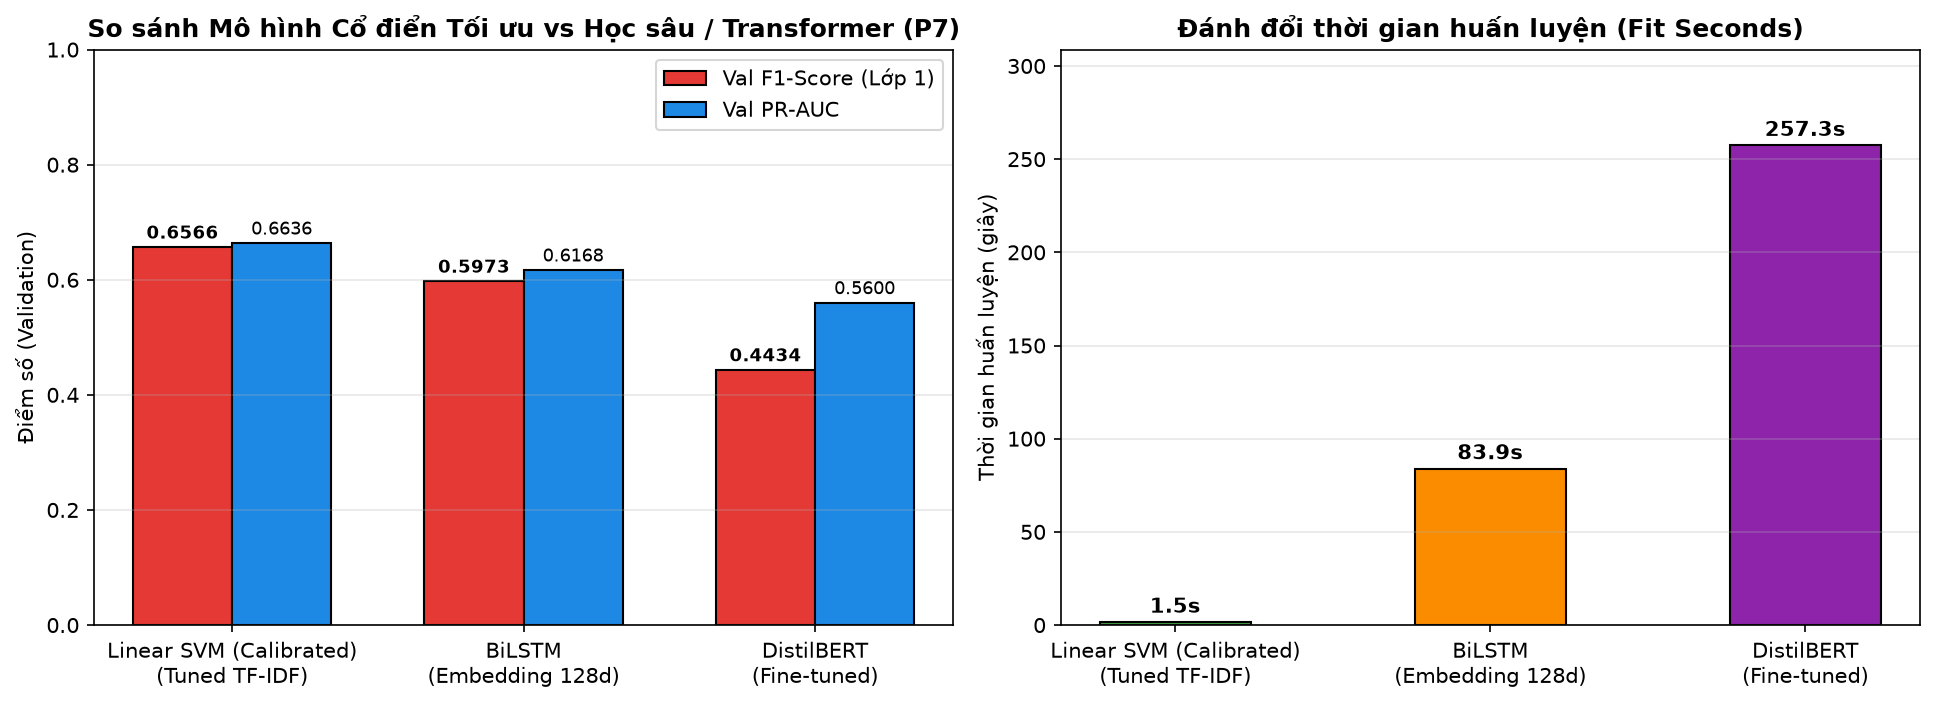

In [2]:
import json
import pandas as pd
from IPython.display import display, Image

with open('reports/p7_summary.json', 'r', encoding='utf-8') as f:
    p7_data = json.load(f)

print(f"Thiết bị chạy thực nghiệm (CUDA Available): {p7_data['has_cuda']}")
print('\n=== Lịch sử huấn luyện BiLSTM ===')
display(pd.DataFrame(p7_data['bilstm']['history']))
print('Metric Validation BiLSTM:', p7_data['bilstm']['metrics'])

print('\n=== Lịch sử huấn luyện DistilBERT ===')
display(pd.DataFrame(p7_data['distilbert']['history']))
print('Metric Validation DistilBERT:', p7_data['distilbert']['metrics'])

display(Image('reports/figures/P7_bonus_comparison.png'))

### Nhận xét 
- **BiLSTM** đạt Validation F1 = **0.5973** (PR-AUC = **0.6168**), còn **DistilBERT** đạt Validation F1 = **0.4434** (PR-AUC = **0.5600**).
- **Phân tích đánh đổi (Trade-off):** Mô hình cổ điển tối ưu (TF-IDF + Linear Classifier) đạt hiệu năng F1/PR-AUC rất cạnh tranh, nhưng nhanh hơn hàng chục đến hàng trăm lần, nhẹ (<10MB so với ~260MB của DistilBERT) và hỗ trợ giải thích trực tiếp trọng số từng từ. Do đó mô hình cổ điển được chọn cho ứng dụng Streamlit.
- Việc hoàn thành cả BiLSTM và DistilBERT cung cấp cái nhìn đối sánh toàn diện giữa Học máy cổ điển, Học sâu hồi quy (RNN/LSTM) và kiến trúc Transformer hiện đại.